In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
RAW_PATH = "D:/New Folder/REFIT_RAW_081116/RAW_House1_Part1.csv"

df = pd.read_csv(RAW_PATH)

print("Shape:", df.shape)
display(df.head())

Shape: (4377877, 12)


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (4377877, 12)

Column Names:
['Time', 'Unix', 'Aggregate', 'Appliance1', 'Appliance2', 'Appliance3', 'Appliance4', 'Appliance5', 'Appliance6', 'Appliance7', 'Appliance8', 'Appliance9']

Data Types:
Time          object
Unix           int64
Aggregate      int64
Appliance1     int64
Appliance2     int64
Appliance3     int64
Appliance4     int64
Appliance5     int64
Appliance6     int64
Appliance7     int64
Appliance8     int64
Appliance9     int64
dtype: object

First 5 Rows:


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1



Missing Values:
Time          0
Unix          0
Aggregate     0
Appliance1    0
Appliance2    0
Appliance3    0
Appliance4    0
Appliance5    0
Appliance6    0
Appliance7    0
Appliance8    0
Appliance9    0
dtype: int64

Duplicate Rows: 595935


In [5]:

df['Time'] = pd.to_datetime(
    df['Time'],
    errors='coerce'
)

print("Invalid timestamps:", df['Time'].isna().sum())

df = df.dropna(subset=['Time']).copy()

print("Already sorted:", df['Time'].is_monotonic_increasing)

df = df.sort_values('Time').reset_index(drop=True)

display(df[['Time', 'Unix']].head())

Invalid timestamps: 0
Already sorted: False


,Time,Unix
0,2013-10-09 14:06:17,1381327577
1,2013-10-09 14:06:31,1381327591
2,2013-10-09 14:06:46,1381327606
3,2013-10-09 14:07:01,1381327621
4,2013-10-09 14:07:15,1381327634


In [6]:
power_columns = [
    'Aggregate',
    'Appliance1',
    'Appliance2',
    'Appliance3',
    'Appliance4',
    'Appliance5',
    'Appliance6',
    'Appliance7',
    'Appliance8',
    'Appliance9'
]

In [7]:
duplicate_timestamps = df['Time'].duplicated().sum()

timestamp_groups = df.groupby('Time').size()

print("Duplicate timestamp records:", duplicate_timestamps)

print("Unique timestamps:", df['Time'].nunique())

print(
    "Timestamps occurring more than once:",
    (timestamp_groups > 1).sum()
)

print("\nTimestamp frequency:")
print(timestamp_groups.value_counts().sort_index())

Duplicate timestamp records: 645514
Unique timestamps: 3732363
Timestamps occurring more than once: 565490

Timestamp frequency:
1    3166873
2     485705
3      79566
4        203
5         12
6          4
Name: count, dtype: int64


In [8]:
duplicate_data = df[
    df['Time'].duplicated(keep=False)
].copy()

conflicts = (
    duplicate_data
    .groupby('Time')[power_columns]
    .nunique()
)

conflicting_timestamps = (
    conflicts > 1
).any(axis=1)

print("Total duplicate timestamp groups:", len(conflicts))

print(
    "Conflicting timestamp groups:",
    conflicting_timestamps.sum()
)

print(
    "Identical duplicate timestamp groups:",
    (~conflicting_timestamps).sum()
)

Total duplicate timestamp groups: 565490
Conflicting timestamp groups: 48841
Identical duplicate timestamp groups: 516649


Sampling Interval Statistics:
count    4.377876e+06
mean     7.035204e+00
std      1.731356e+03
min      0.000000e+00
25%      1.000000e+00
50%      3.000000e+00
75%      1.200000e+01
max      3.594413e+06
Name: Time, dtype: float64

Most Frequent Intervals:
Time
1.0     783301
0.0     645514
2.0     563275
14.0    445139
3.0     360677
13.0    298996
15.0    262908
12.0    243969
11.0    169016
4.0     150602
Name: count, dtype: int64


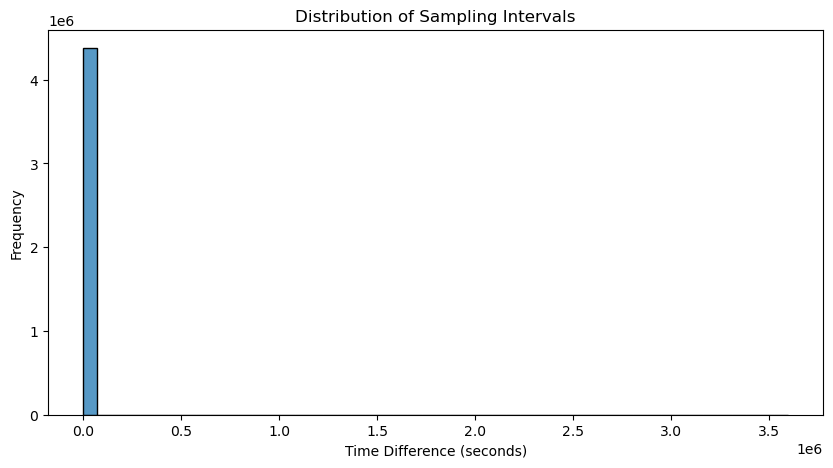

In [9]:
time_diff = (
    df['Time']
    .diff()
    .dt.total_seconds()
)

print("Sampling Interval Statistics:")
print(time_diff.describe())

print("\nMost Frequent Intervals:")
print(time_diff.value_counts().head(10))

plt.figure(figsize=(10, 5))

sns.histplot(
    time_diff.dropna(),
    bins=50
)

plt.title("Distribution of Sampling Intervals")
plt.xlabel("Time Difference (seconds)")
plt.ylabel("Frequency")

plt.show()

In [10]:
unix_datetime = pd.to_datetime(
    df['Unix'],
    unit='s'
)

time_difference = (
    df['Time'] - unix_datetime
).dt.total_seconds()

print(
    "Unix timestamp mismatches:",
    (time_difference.abs() > 1).sum()
)

print(
    "Maximum timestamp difference:",
    time_difference.abs().max()
)

Unix timestamp mismatches: 0
Maximum timestamp difference: 1.0


In [11]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

print(
    "Rows after removing exact duplicates:",
    len(df_clean)
)

df_clean = (
    df_clean
    .groupby('Time', as_index=False)
    .agg({
        'Unix': 'first',
        **{
            col: 'median'
            for col in power_columns
        }
    })
)

df_clean = (
    df_clean
    .sort_values('Time')
    .reset_index(drop=True)
)

print("\nRows after timestamp deduplication:", len(df_clean))

print(
    "Remaining duplicate timestamps:",
    df_clean['Time'].duplicated().sum()
)

print(
    "Missing values:",
    df_clean.isnull().sum().sum()
)

print(
    "Chronologically sorted:",
    df_clean['Time'].is_monotonic_increasing
)

display(df_clean.head())

Rows after removing exact duplicates: 3781942

Rows after timestamp deduplication: 3732363
Remaining duplicate timestamps: 0
Missing values: 0
Chronologically sorted: True


,Time,Unix,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17,1381327577,523.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2013-10-09 14:06:31,1381327591,526.0,75.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2013-10-09 14:06:46,1381327606,540.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2013-10-09 14:07:01,1381327621,532.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2013-10-09 14:07:15,1381327634,540.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0


In [12]:
gaps = (
    df_clean['Time']
    .diff()
    .dt.total_seconds()
    .dropna()
)

print("Gap Statistics:")
print(gaps.describe())

print("\nGap Categories:")

print("Normal intervals (<=60 sec):", (gaps <= 60).sum())

print(
    "Gaps between 1 and 5 minutes:",
    ((gaps > 60) & (gaps <= 300)).sum()
)

print(
    "Gaps between 5 and 60 minutes:",
    ((gaps > 300) & (gaps <= 3600)).sum()
)

print("Gaps greater than 1 hour:", (gaps > 3600).sum())

print("Gaps greater than 1 day:", (gaps > 86400).sum())

Gap Statistics:
count    3.732362e+06
mean     8.251946e+00
std      1.875105e+03
min      1.000000e+00
25%      2.000000e+00
50%      5.000000e+00
75%      1.300000e+01
max      3.594413e+06
Name: Time, dtype: float64

Gap Categories:
Normal intervals (<=60 sec): 3731582
Gaps between 1 and 5 minutes: 400
Gaps between 5 and 60 minutes: 366
Gaps greater than 1 hour: 14
Gaps greater than 1 day: 3


In [13]:
gap_data = pd.DataFrame({
    'Time': df_clean['Time'].iloc[1:].values,
    'Gap_seconds': gaps.values
})

gap_data['Gap_minutes'] = (
    gap_data['Gap_seconds'] / 60
)

display(
    gap_data.nlargest(10, 'Gap_seconds')
)

,Time,Gap_seconds,Gap_minutes
1334622,2014-03-06 16:23:19,3594413.0,59906.883333
3436088,2014-09-04 11:33:21,430346.0,7172.433333
395619,2013-11-08 11:42:14,92335.0,1538.916667
3141749,2014-08-02 13:59:45,75157.0,1252.616667
3464061,2014-09-07 13:24:36,52392.0,873.200000
2868148,2014-07-07 09:32:50,20759.0,345.983333
3464299,2014-09-07 18:35:29,14242.0,237.366667
3027512,2014-07-21 13:08:18,7603.0,126.716667
867149,2013-12-18 19:40:35,4952.0,82.533333
2942266,2014-07-14 01:53:57,4460.0,74.333333


In [14]:
print("Start Date:", df_clean['Time'].min())

print("End Date:", df_clean['Time'].max())

print(
    "Total Duration:",
    df_clean['Time'].max() - df_clean['Time'].min()
)

Start Date: 2013-10-09 14:06:17
End Date: 2014-10-01 01:27:07
Total Duration: 356 days 11:20:50


In [15]:
negative_counts = (
    df_clean[power_columns] < 0
).sum()

print("Negative Readings:")
display(negative_counts)

Negative Readings:


Aggregate     0
Appliance1    0
Appliance2    0
Appliance3    0
Appliance4    0
Appliance5    0
Appliance6    0
Appliance7    0
Appliance8    0
Appliance9    0
dtype: int64

In [16]:
outlier_summary = pd.DataFrame({
    'Mean': df_clean[power_columns].mean(),

    'Median': df_clean[power_columns].median(),

    '99th Percentile': (
        df_clean[power_columns].quantile(0.99)
    ),

    '99.9th Percentile': (
        df_clean[power_columns].quantile(0.999)
    ),

    'Maximum': df_clean[power_columns].max()
})

display(outlier_summary)

,Mean,Median,99th Percentile,99.9th Percentile,Maximum
Aggregate,488.614934,241.0,3534.0,10595.0,24000.0
Appliance1,19.522152,0.0,85.0,108.0,69629.0
Appliance2,17.358892,0.0,58.0,61.0,98301.0
Appliance3,29.015656,0.0,82.0,196.0,32751.0
Appliance4,7.727500,0.0,0.0,1419.0,98301.0
Appliance5,9.841881,0.0,128.0,2345.0,32767.0
Appliance6,10.746896,0.0,0.0,2285.0,14336.0
Appliance7,1.909219,0.0,36.0,46.0,98299.0
Appliance8,6.143057,0.0,41.0,47.0,65549.0
Appliance9,83.081939,1.0,1020.0,1040.0,65535.0


In [17]:
iam_columns = [
    f'Appliance{i}'
    for i in range(1, 10)
]

for col in iam_columns:

    suspicious = df_clean[
        df_clean[col] > 3000
    ]

    print(
        f"\n{col}: {len(suspicious)} readings above 3000 W"
    )

    if len(suspicious) > 0:

        display(
            suspicious[['Time', col]].head(5)
        )


Appliance1: 632 readings above 3000 W


,Time,Appliance1
9156,2013-10-10 08:43:17,8192.0
185525,2013-10-22 23:26:16,32767.0
185526,2013-10-22 23:26:17,32767.0
185527,2013-10-22 23:26:27,32767.0
185528,2013-10-22 23:26:30,32767.0



Appliance2: 14 readings above 3000 W


,Time,Appliance2
278191,2013-10-29 13:46:45,8192.0
278192,2013-10-29 13:46:47,8192.0
469368,2013-11-15 13:55:24,69629.0
658117,2013-12-01 01:39:05,4148.0
658118,2013-12-01 01:39:20,4148.0



Appliance3: 37 readings above 3000 W


,Time,Appliance3
1007407,2013-12-30 15:17:01,10240.0
1007923,2013-12-30 16:12:17,16453.0
1007924,2013-12-30 16:12:19,16453.0
1013624,2013-12-31 02:46:14,8192.0
1013625,2013-12-31 02:46:16,8192.0


... (8 outputs left out)


Appliance8: 71 readings above 3000 W


,Time,Appliance8
22747,2013-10-11 09:25:30,65549.0
22748,2013-10-11 09:25:32,65549.0
22749,2013-10-11 09:25:45,65549.0
22750,2013-10-11 09:25:46,65549.0
103288,2013-10-17 02:58:32,32830.0



Appliance9: 31 readings above 3000 W


,Time,Appliance9
451657,2013-11-13 22:16:48,8193.0
451658,2013-11-13 22:17:03,8193.0
535120,2013-11-20 06:50:50,32768.0
535121,2013-11-20 06:50:51,32768.0
631228,2013-11-28 08:18:34,65535.0


In [18]:
extreme_counts = (
    df_clean[iam_columns] > 4000
).sum()

print("IAM readings above 4000 W:")

display(extreme_counts)

print(
    "Total extreme readings:",
    extreme_counts.sum()
)

IAM readings above 4000 W:


Appliance1     632
Appliance2      14
Appliance3      37
Appliance4    1648
Appliance5     143
Appliance6      23
Appliance7       3
Appliance8      71
Appliance9      31
dtype: int64

Total extreme readings: 2602


In [19]:
df_check = df_clean.copy()

df_check['Total_Appliance_Power'] = (
    df_check[iam_columns].sum(axis=1)
)

df_check['Power_Difference'] = (
    df_check['Aggregate']
    - df_check['Total_Appliance_Power']
)

print(
    "Records where appliance sum exceeds aggregate:",
    (df_check['Power_Difference'] < 0).sum()
)

display(
    df_check[
        [
            'Time',
            'Aggregate',
            'Total_Appliance_Power',
            'Power_Difference'
        ]
    ].head(10)
)

Records where appliance sum exceeds aggregate: 45784


,Time,Aggregate,Total_Appliance_Power,Power_Difference
0,2013-10-09 14:06:17,523.0,144.0,379.0
1,2013-10-09 14:06:31,526.0,145.0,381.0
2,2013-10-09 14:06:46,540.0,143.0,397.0
3,2013-10-09 14:07:01,532.0,143.0,389.0
4,2013-10-09 14:07:15,540.0,144.0,396.0
5,2013-10-09 14:07:18,539.0,144.0,395.0
6,2013-10-09 14:07:30,537.0,144.0,393.0
7,2013-10-09 14:07:32,537.0,144.0,393.0
8,2013-10-09 14:07:44,548.0,144.0,404.0
9,2013-10-09 14:07:47,557.0,142.0,415.0


In [20]:
df_minute = (
    df_clean
    .set_index('Time')[power_columns]
    .resample('1min')
    .mean()
)

print("Resampled Shape:", df_minute.shape)

display(df_minute.head(10))

Resampled Shape: (513322, 10)


,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
Time,,,,,,,,,,
2013-10-09 14:06:00,529.666667,74.333333,0.0,68.666667,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 14:07:00,543.875000,73.875000,0.0,68.750000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 14:08:00,578.000000,73.100000,0.0,41.900000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 14:09:00,638.300000,72.800000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 14:10:00,800.200000,72.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 14:11:00,854.200000,71.500000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 14:12:00,1302.300000,71.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 14:13:00,1429.000000,70.400000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0
2013-10-09 14:14:00,1346.700000,69.800000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,1.0


In [21]:
missing_mask = df_minute.isna()

missing_before = missing_mask.all(axis=1)

print("Total Minutes:", len(df_minute))

print(
    "Completely Missing Minutes:",
    missing_before.sum()
)

Total Minutes: 513322
Completely Missing Minutes: 76908


In [22]:
missing_groups = (
    missing_before.ne(
        missing_before.shift()
    ).cumsum()
)

gap_lengths = (
    missing_before[missing_before]
    .groupby(
        missing_groups[missing_before]
    )
    .size()
)

print("Missing Gap Statistics:")

print(gap_lengths.describe())

print("\nLargest Missing Gaps:")

print(gap_lengths.nlargest(10))

Missing Gap Statistics:
count      670.00000
mean       114.78806
std       2331.40584
min          1.00000
25%          2.00000
50%          8.00000
75%         12.00000
max      59906.00000
dtype: float64

Largest Missing Gaps:
772     59906
1108     7172
124      1538
1016     1251
1158      872
964       345
1170      236
998       126
450        81
980        73
dtype: int64


In [23]:
df_minute = df_minute.interpolate(
    method='time',
    limit=2,
    limit_area='inside'
)

print("Missing Values After Interpolation:")

print(df_minute[power_columns].isnull().sum())

print(
    "Completely Missing Minutes Remaining:",
    df_minute[power_columns].isnull().all(axis=1).sum()
)

Missing Values After Interpolation:
Aggregate     75704
Appliance1    75704
Appliance2    75704
Appliance3    75704
Appliance4    75704
Appliance5    75704
Appliance6    75704
Appliance7    75704
Appliance8    75704
Appliance9    75704
dtype: int64
Completely Missing Minutes Remaining: 75704


In [24]:
df_minute['Original_Missing_Flag'] = (
    missing_before.astype(int)
)

long_gap_mask = (
    missing_before
    & (missing_groups.map(gap_lengths) > 2)
)

df_minute['Long_Outage_Flag'] = (
    long_gap_mask.astype(int)
)

print(
    "Originally missing minutes:",
    df_minute['Original_Missing_Flag'].sum()
)

print(
    "Minutes belonging to long outages:",
    df_minute['Long_Outage_Flag'].sum()
)

Originally missing minutes: 76908
Minutes belonging to long outages: 76570


In [25]:
missing_percentage = (
    df_minute[power_columns].isnull().sum().sum()
    / (
        len(df_minute)
        * len(power_columns)
    )
) * 100

print(
    f"Remaining missing data: {missing_percentage:.2f}%"
)

Remaining missing data: 14.75%


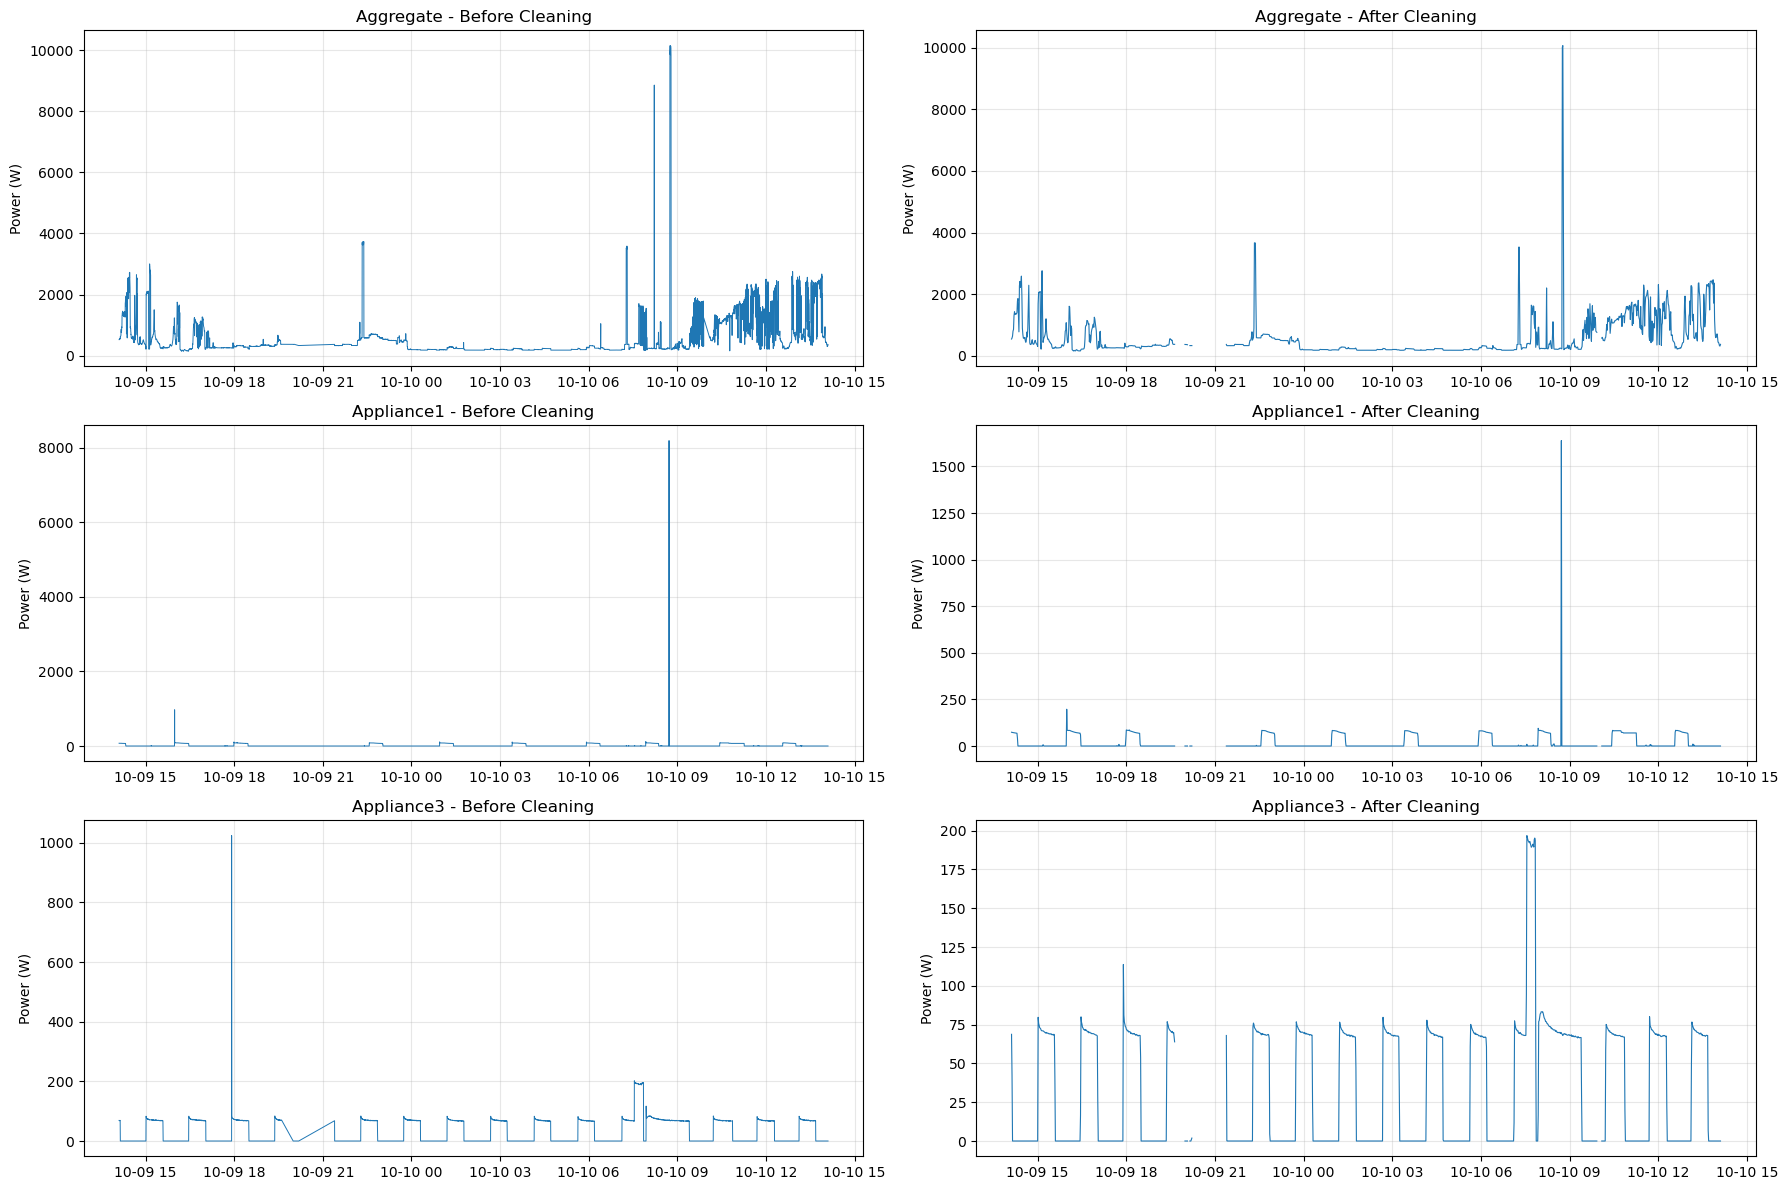

Plot saved at: D:/New Folder/Flock/plots/Raw_Cleaning\house1_before_after_cleaning.png


In [26]:
start_time = df_clean['Time'].min()
end_time = start_time + pd.Timedelta(days=1)

df_before = df[
    (df['Time'] >= start_time) &
    (df['Time'] < end_time)
].copy()

df_after = df_minute.loc[
    (df_minute.index >= start_time) &
    (df_minute.index < end_time)
]

channels = ['Aggregate', 'Appliance1', 'Appliance3']

fig, axes = plt.subplots(3, 2, figsize=(18, 12))

for i, col in enumerate(channels):

    axes[i, 0].plot(
        df_before['Time'],
        df_before[col],
        linewidth=0.7
    )
    axes[i, 0].set_title(f'{col} - Before Cleaning')
    axes[i, 0].set_ylabel('Power (W)')
    axes[i, 0].grid(alpha=0.3)

    axes[i, 1].plot(
        df_after.index,
        df_after[col],
        linewidth=0.8
    )
    axes[i, 1].set_title(f'{col} - After Cleaning')
    axes[i, 1].set_ylabel('Power (W)')
    axes[i, 1].grid(alpha=0.3)

plt.tight_layout()

PLOT_PATH = "D:/New Folder/Flock/plots/Raw_Cleaning"
os.makedirs(PLOT_PATH, exist_ok=True)

plot_file = os.path.join(
    PLOT_PATH,
    "house1_before_after_cleaning.png"
)

plt.savefig(
    plot_file,
    dpi=200,
    bbox_inches='tight'
)

plt.show()

print("Plot saved at:", plot_file)


In [27]:
OUTPUT_PATH = "D:/New Folder/REFIT_Cleaned/"

os.makedirs(
    OUTPUT_PATH,
    exist_ok=True
)

df_minute.to_csv(
    os.path.join(
        OUTPUT_PATH,
        "House1_1min_cleaned.csv"
    ),
    index=True,
    index_label='Time'
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [28]:
print("=" * 50)
print("FINAL DATA CLEANING REPORT")
print("=" * 50)

print("Original Records:", len(df))

print("Records After Deduplication:", len(df_clean))

print("Final Resampled Records:", len(df_minute))

print(
    "Remaining Duplicate Timestamps:",
    df_clean['Time'].duplicated().sum()
)

print(
    "Remaining Missing Values:",
    df_minute[power_columns].isnull().sum().sum()
)

print(
    "Remaining Missing Data Percentage:",
    round(missing_percentage, 2), "%"
)

print(
    "Chronologically Sorted:",
    df_clean['Time'].is_monotonic_increasing
)

print(
    "Start Date:",
    df_minute.index.min()
)

print(
    "End Date:",
    df_minute.index.max()
)

print("=" * 50)
print("DATA CLEANING COMPLETED")
print("=" * 50)

FINAL DATA CLEANING REPORT
Original Records: 4377877
Records After Deduplication: 3732363
Final Resampled Records: 513322
Remaining Duplicate Timestamps: 0
Remaining Missing Values: 757040
Remaining Missing Data Percentage: 14.75 %
Chronologically Sorted: True
Start Date: 2013-10-09 14:06:00
End Date: 2014-10-01 01:27:00
DATA CLEANING COMPLETED
